### DATA SCIENCE PROJECT : BANK-RUPTCY PREVENTION

In [95]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [96]:
df = pd.read_csv('Bankruptcy_prevention_Dataset.csv', sep = ';')
df.columns = df.columns.str.strip()
df.head()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
0,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
1,0.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
2,1.0,0.0,0.0,0.0,0.0,1.0,bankruptcy
3,0.5,0.0,0.0,0.5,0.0,1.0,bankruptcy
4,1.0,1.0,0.0,0.0,0.0,1.0,bankruptcy


In [97]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   industrial_risk        250 non-null    float64
 1   management_risk        250 non-null    float64
 2   financial_flexibility  250 non-null    float64
 3   credibility            250 non-null    float64
 4   competitiveness        250 non-null    float64
 5   operating_risk         250 non-null    float64
 6   class                  250 non-null    object 
dtypes: float64(6), object(1)
memory usage: 13.8+ KB


In [98]:
df.shape

(250, 7)

In [99]:
df.size

1750

In [100]:
df.describe()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk
count,250.000000,250.000000,250.000000,250.000000,250.000000,250.000000
mean,0.518000,0.614000,0.376000,0.470000,0.476000,0.570000
std,0.411526,0.410705,0.401583,0.415682,0.440682,0.434575
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.500000,0.000000,0.000000,0.000000,0.000000
50%,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000
75%,1.000000,1.000000,0.500000,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [101]:
df.describe(include = 'O')

,class
count,250
unique,2
top,non-bankruptcy
freq,143


In [102]:
df.isnull().sum()

industrial_risk          0
management_risk          0
financial_flexibility    0
credibility              0
competitiveness          0
operating_risk           0
class                    0
dtype: int64

In [103]:
df.isnull().sum().sum()

np.int64(0)

In [104]:
df.duplicated().sum()

np.int64(147)

In [105]:
df.duplicated().sum().sum()/len(df)*100

np.float64(58.8)

### Duplicate Records

The dataset contained **147 duplicate rows (58.8%)**. I decided to retain these records to preserve the original dataset rather than discard a significant portion of the available data.

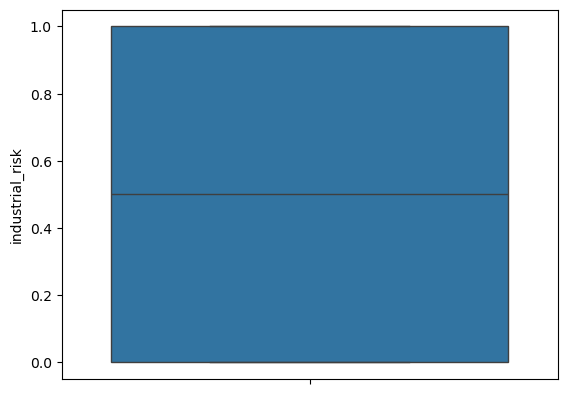

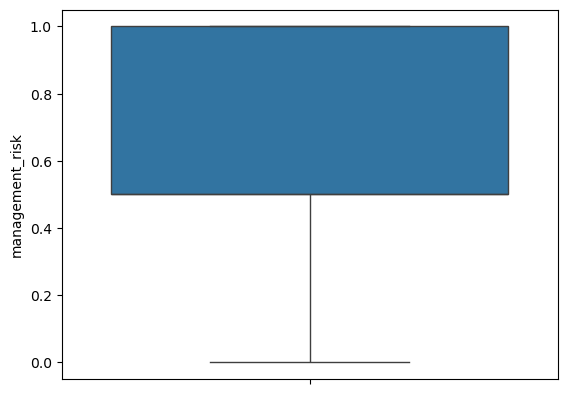

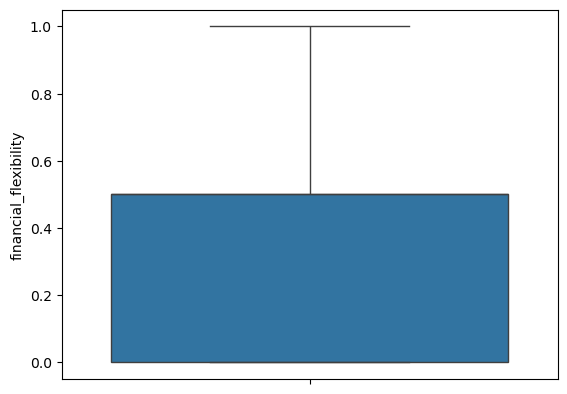

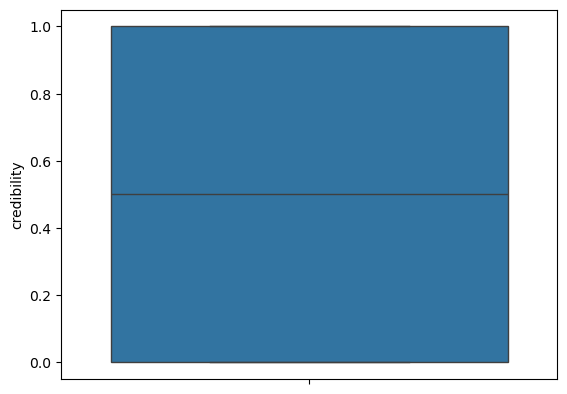

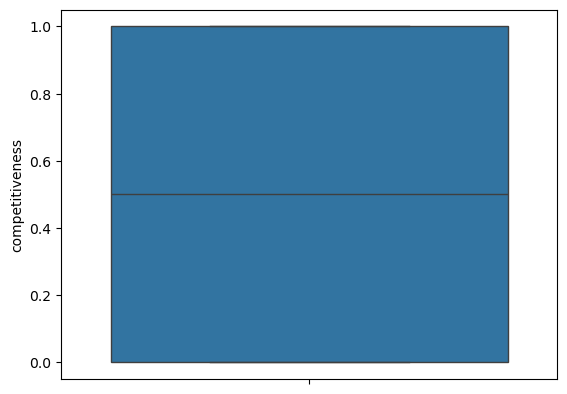

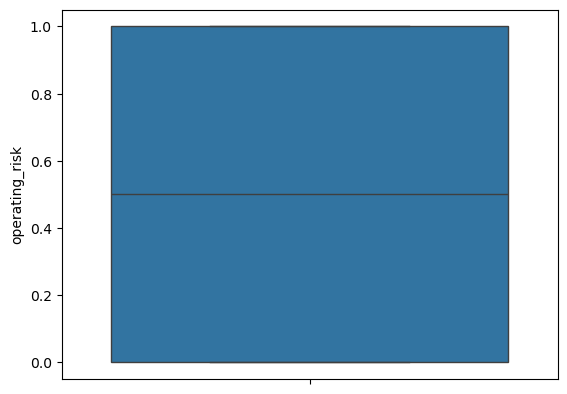

In [106]:
for i in df.select_dtypes(include = ['int64', 'float64']).columns :
    sns.boxplot(df[i])
    plt.show()

### Outlier Detection

I used **box plots** to check for unusually distant values across the six input features. No significant outliers were identified in the dataset, so no outlier removal was required.

In [107]:
df.columns

Index(['industrial_risk', 'management_risk', 'financial_flexibility',
       'credibility', 'competitiveness', 'operating_risk', 'class'],
      dtype='object')

In [108]:
print('Value counts :')
for i in df.select_dtypes(include = ['int64', 'float64']).columns:
    print(df[i].value_counts())

Value counts :
industrial_risk
1.0    89
0.5    81
0.0    80
Name: count, dtype: int64
management_risk
1.0    119
0.5     69
0.0     62
Name: count, dtype: int64
financial_flexibility
0.0    119
0.5     74
1.0     57
Name: count, dtype: int64
credibility
0.0    94
1.0    79
0.5    77
Name: count, dtype: int64
competitiveness
0.0    103
1.0     91
0.5     56
Name: count, dtype: int64
operating_risk
1.0    114
0.0     79
0.5     57
Name: count, dtype: int64


In [109]:
print('Unique Values :')
for i in df.select_dtypes(include = ['int64', 'float64']).columns:
    print(i, ':', df[i].unique())

Unique Values :
industrial_risk : [0.5 0.  1. ]
management_risk : [1.  0.  0.5]
financial_flexibility : [0.  0.5 1. ]
credibility : [0.  0.5 1. ]
competitiveness : [0.  0.5 1. ]
operating_risk : [0.5 1.  0. ]


In [110]:
print('N-unique Values :')
for i in df.select_dtypes(include = ['int64', 'float64']).columns:
    print(i, ':', df[i].nunique())

N-unique Values :
industrial_risk : 3
management_risk : 3
financial_flexibility : 3
credibility : 3
competitiveness : 3
operating_risk : 3


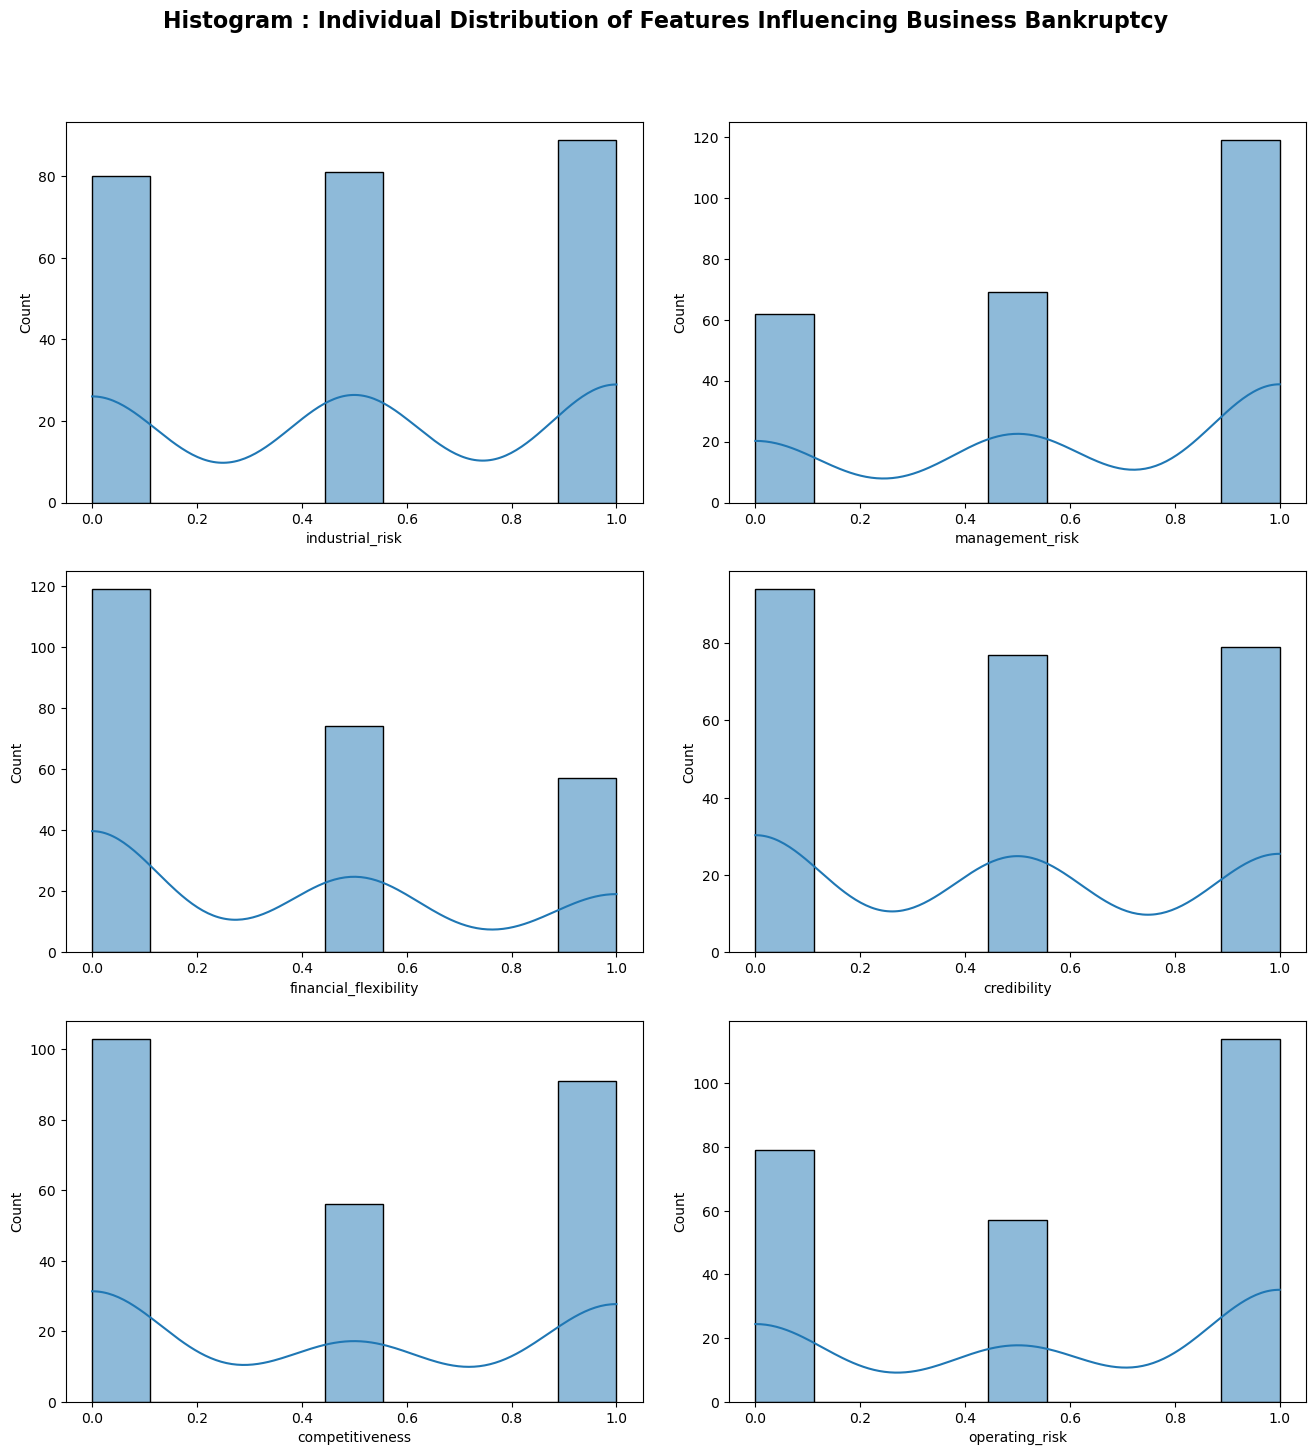

In [111]:
fig, axes = plt.subplots(3, 2, figsize = (16, 16))
plt.suptitle('Histogram : Individual Distribution of Features Influencing Business Bankruptcy', fontsize = 16, fontweight = 'bold', y = 0.98)
fig.subplots_adjust(top = 0.91, hspace = 0.18, wspace = 0.15)
sns.histplot(df['industrial_risk'], kde = True, ax = axes[0,0])
sns.histplot(df['management_risk'], kde = True, ax = axes[0,1])
sns.histplot(df['financial_flexibility'], kde = True, ax = axes[1,0])
sns.histplot(df['credibility'], kde = True, ax = axes[1,1])
sns.histplot(df['competitiveness'], kde = True, ax = axes[2,0])
sns.histplot(df['operating_risk'], kde = True, ax = axes[2,1])
plt.savefig("feature_distributions.png", dpi=300, bbox_inches="tight")

In [112]:
feat = df.select_dtypes(include = ['int64', 'float64'])
print(f'''Skewness Values of Features Influencing Business Bankruptcy :\n{feat.skew()}''')

Skewness Values of Features Influencing Business Bankruptcy :
industrial_risk         -0.067011
management_risk         -0.444701
financial_flexibility    0.479134
credibility              0.112955
competitiveness          0.093906
operating_risk          -0.275547
dtype: float64


### Feature Distributions and Skewness

I used **histograms** to understand how the values are distributed across the six features. Since each feature contains only three possible ratings (0, 0.5 and 1), the plots help identify which rating levels occur more frequently.

I also calculated **skewness** to understand the direction and extent of asymmetry in each distribution.

- **Industrial Risk (-0.067) :** Almost symmetric.
- **Management Risk (-0.445) :** Slightly negatively skewed.
- **Financial Flexibility (0.479) :** Slightly positively skewed.
- **Credibility (0.113) :** Almost symmetric.
- **Competitiveness (0.094) :** Almost symmetric.
- **Operating Risk (-0.276) :** Slightly negatively skewed.

Overall, the skewness values are relatively close to zero, indicating **no strong skewness** in the feature distributions.

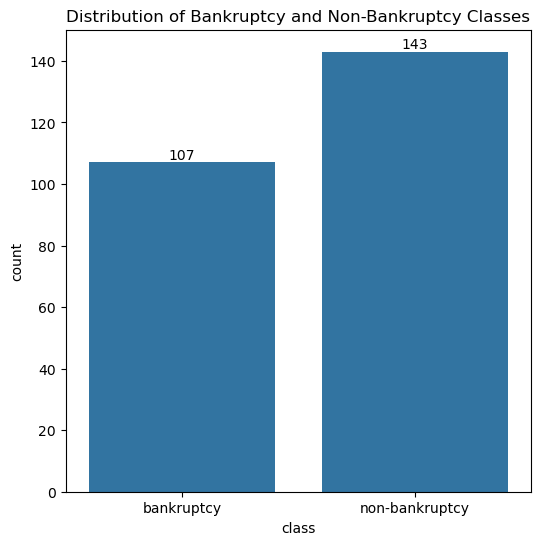

In [113]:
plt.figure(figsize = (6,6))
plt.title('Distribution of Bankruptcy and Non-Bankruptcy Classes')
ax = sns.countplot(x = df['class'])
for container in ax.containers:
    ax.bar_label(container)
plt.savefig("target_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

### Target Class Distribution

The target variable contains **107 Bankruptcy records** and **143 Non-bankruptcy records**.

The dataset has a slightly higher number of non-bankruptcy cases, but both classes are reasonably represented. This distribution is important to consider when evaluating model performance.

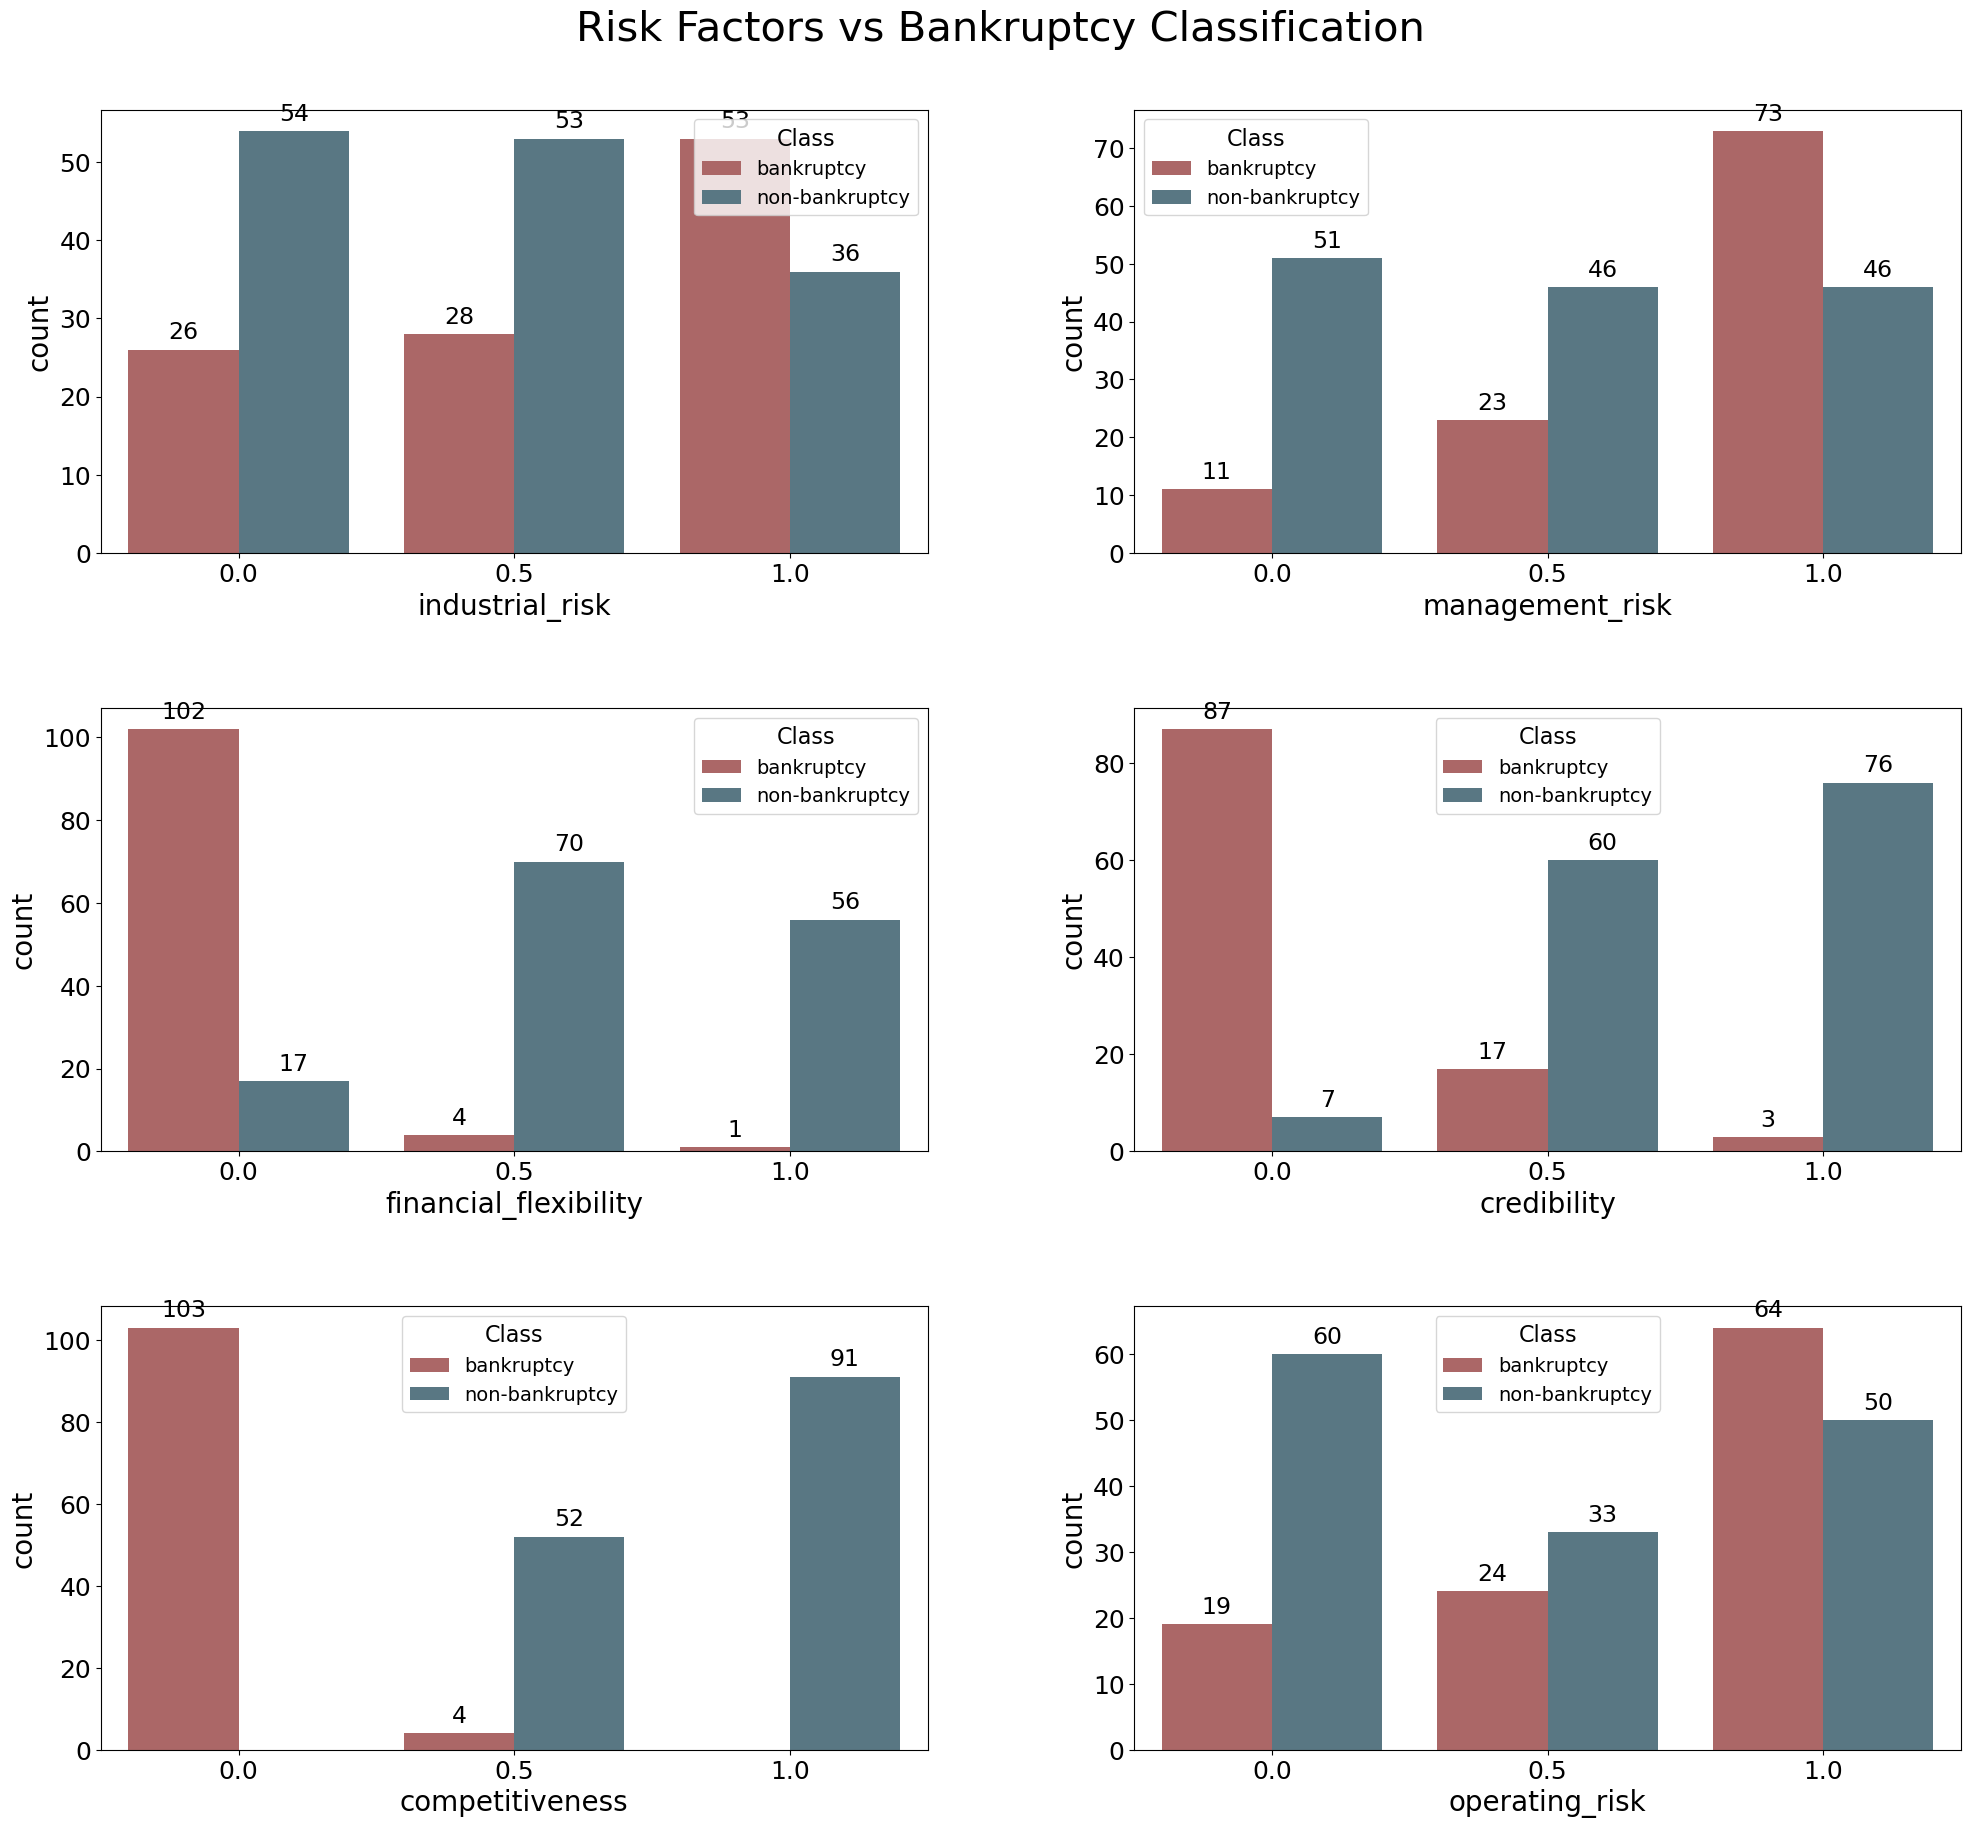

In [114]:
fig, axes = plt.subplots(3, 2, figsize = (24, 20))

fig.suptitle('Risk Factors vs Bankruptcy Classification', fontsize = 30)

sns.countplot(data = df, x = 'industrial_risk', hue = 'class',
              palette = {'bankruptcy': '#B65C5C', 'non-bankruptcy': '#527A8A'}, ax = axes[0,0])

sns.countplot(data = df, x = 'management_risk', hue = 'class',
              palette = {'bankruptcy': '#B65C5C', 'non-bankruptcy': '#527A8A'}, ax = axes[0,1])

sns.countplot(data = df, x = 'financial_flexibility', hue = 'class',
              palette = {'bankruptcy': '#B65C5C', 'non-bankruptcy': '#527A8A'}, ax = axes[1,0])

sns.countplot(data = df, x = 'credibility', hue = 'class',
              palette = {'bankruptcy': '#B65C5C', 'non-bankruptcy': '#527A8A'}, ax = axes[1,1])

sns.countplot(data = df, x = 'competitiveness', hue = 'class',
              palette = {'bankruptcy': '#B65C5C', 'non-bankruptcy': '#527A8A'}, ax = axes[2,0])

sns.countplot(data = df, x = 'operating_risk', hue = 'class',
              palette = {'bankruptcy': '#B65C5C', 'non-bankruptcy': '#527A8A'}, ax = axes[2,1])

for ax in axes.flat:
    ax.set_xlabel(ax.get_xlabel(), fontsize = 20)
    ax.set_ylabel(ax.get_ylabel(), fontsize = 20)
    ax.tick_params(axis = 'both', labelsize = 18)

    # Increase legend font size
    ax.legend(title = 'Class', fontsize = 14, title_fontsize = 16)

    # Increase count numbers above bars
    for container in ax.containers:
        ax.bar_label(container, fontsize = 17, padding = 4)

fig.subplots_adjust(top = 0.93, hspace = 0.35, wspace = 0.25)
plt.savefig("feature_comparisons.png", dpi=300, bbox_inches="tight")

plt.show()

### Feature-wise Comparison

I used **count plots** to compare the distribution of bankruptcy and non-bankruptcy cases across different feature levels.

- **Industrial Risk & Management Risk:** Higher risk levels show more bankruptcy cases.
- **Operating Risk:** Higher risk levels also tend to have more bankruptcy cases.
- **Financial Flexibility, Credibility & Competitiveness:** Higher ratings are mostly associated with non-bankruptcy cases.

Overall, the plots highlight how different business factors are associated with bankruptcy outcomes in the dataset.

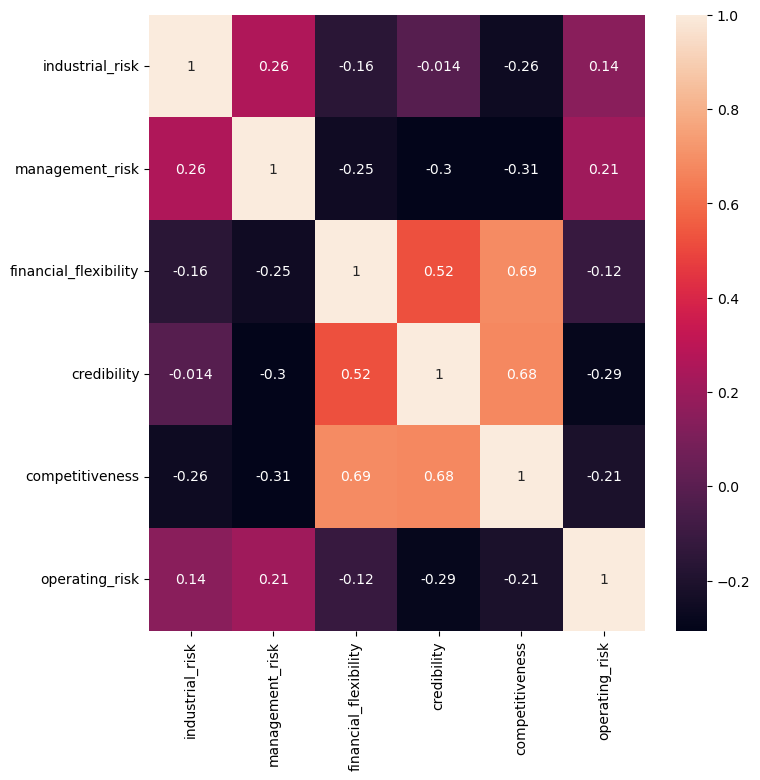

In [115]:
plt.figure(figsize = (8, 8))
sns.heatmap(df.corr(numeric_only = True), annot = True)

plt.savefig("correlation_heatmap.png", dpi=300, bbox_inches="tight")

### Correlation Heatmap

The correlation heatmap helps understand the relationships between the six input features.

**Financial Flexibility, Credibility and Competitiveness** show relatively stronger positive correlations with one another. The strongest relationship is between Financial Flexibility and Competitiveness, with a correlation of approximately **0.69**.

Overall, the heatmap helps identify how features are related to each other. However, **correlation does not imply causation**.

In [116]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['class'] = le.fit_transform(df['class'])

In [117]:
x = df.drop(columns = 'class')
y = df['class']

In [118]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 100, stratify=y)

In [119]:
profile_check = df.groupby(
    list(x.columns)
)['class'].nunique()

print("Unique feature profiles:", profile_check.shape[0])

print("Profiles with conflicting labels:",
      (profile_check > 1).sum())

Unique feature profiles: 103
Profiles with conflicting labels: 0


### Checking Duplicate Feature Profiles

I grouped the records using all six input features to identify unique feature combinations and check whether identical profiles had different target labels.

- **103 unique feature profiles** were identified.
- **0 conflicting labels** were found, meaning identical feature profiles always had the same target class.

This confirms that retaining duplicate records does not introduce conflicting labels for identical input combinations.

In [120]:
from sklearn.model_selection import GroupShuffleSplit

groups = pd.factorize(
    df[list(x.columns)].apply(tuple, axis=1)
)[0]

gss = GroupShuffleSplit(
    n_splits = 1,
    test_size = 0.2,
    random_state = 100
)

train_idx, test_idx = next(gss.split(x, y, groups=groups))

x_train = x.iloc[train_idx]
x_test = x.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training rows:", x_train.shape[0])
print("Testing rows:", x_test.shape[0])

Training rows: 204
Testing rows: 46


### Group-Based Train-Test Split

Since the dataset contains duplicate records, a regular random split could place identical feature profiles in both training and test sets, leading to **data leakage**.

I used **GroupShuffleSplit** to keep identical feature profiles together, ensuring they appear entirely in either the training or test set.

The dataset was split into:
- **Training set:** 204 records (81.6%)
- **Testing set:** 46 records (18.4%)

This helps evaluate the model on feature profiles it hasn't encountered during training.

In [121]:
print("Overlapping profiles:",
      len(set(groups[train_idx]) & set(groups[test_idx])))

Overlapping profiles: 0


### Verifying the Split

I checked whether any feature profiles were shared between the training and test sets.

The result shows **0 overlapping profiles**, confirming that identical feature combinations were successfully kept separate during the split.

This helps prevent **data leakage** and makes the model evaluation more reliable.

In [122]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

x_train_scaled = sc.fit_transform(x_train)
x_test_scaled = sc.transform(x_test)

### Logistic Regression

In [123]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()
lr.fit(x_train_scaled, y_train)

lr_train_pred = lr.predict(x_train_scaled)
lr_test_pred = lr.predict(x_test_scaled)

from sklearn.metrics import accuracy_score, f1_score
print(f" accuracy_score of training data is : {accuracy_score(y_train, lr_train_pred)}")
print(f" accuracy_score of testing data is : {accuracy_score(y_test, lr_test_pred)}")
print(f" f1_score of training data is : {f1_score(y_train, lr_train_pred)}")
print(f" f1_score of testing  data is : {f1_score(y_test, lr_test_pred)}")

 accuracy_score of training data is : 0.9950980392156863
 accuracy_score of testing data is : 1.0
 f1_score of training data is : 0.9955156950672646
 f1_score of testing  data is : 1.0


In [124]:
from sklearn.metrics import classification_report
print(classification_report(y_test, lr_test_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        32

    accuracy                           1.00        46
   macro avg       1.00      1.00      1.00        46
weighted avg       1.00      1.00      1.00        46



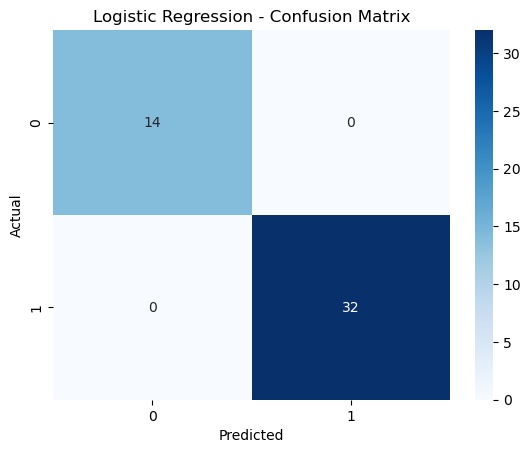

In [125]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, lr_test_pred)

sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression - Confusion Matrix')
plt.savefig("logistic_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [126]:
sigmoid = lr.predict_proba(x_test_scaled)[:, 1]

In [127]:
from sklearn.metrics import roc_auc_score,roc_curve
auc_score = roc_auc_score(y_test,sigmoid)
auc_score

1.0

In [128]:
roc_curve(y_test,sigmoid)

(array([0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.28571429, 0.85714286, 1.        ]),
 array([0.     , 0.0625 , 0.25   , 0.28125, 0.34375, 0.46875, 0.5    ,
        0.625  , 0.6875 , 0.75   , 0.8125 , 1.     , 1.     , 1.     ,
        1.     ]),
 array([       inf, 0.99995551, 0.99945556, 0.99921222, 0.99906556,
        0.99894845, 0.99796234, 0.99426298, 0.98482915, 0.97984652,
        0.97108046, 0.65552923, 0.02036558, 0.00449597, 0.00343079]))

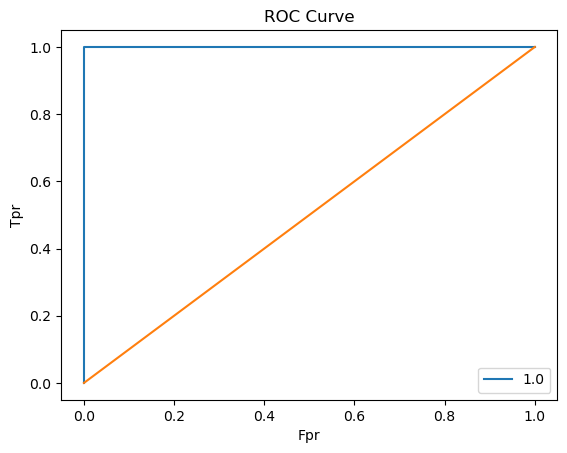

In [129]:
fpr,tpr,thr = roc_curve(y_test,sigmoid)
plt.plot(fpr,tpr,label = f'{auc_score}')
plt.plot([0,1])
plt.xlabel('Fpr')
plt.ylabel('Tpr')
plt.title('ROC Curve')
plt.legend()
plt.savefig("logistic_roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

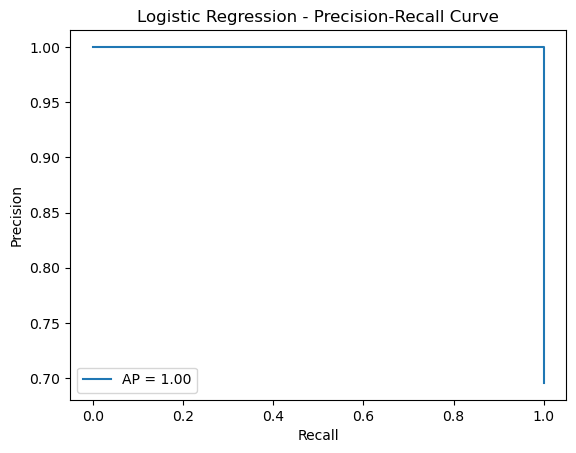

In [130]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, thresholds = precision_recall_curve(y_test, sigmoid)

ap_score = average_precision_score(y_test, sigmoid)

plt.plot(recall, precision, label = f'AP = {ap_score:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Logistic Regression - Precision-Recall Curve')
plt.legend()
plt.savefig("logistic_precision_recall_curve.png", dpi=300, bbox_inches="tight")
plt.show()

In [131]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline

# Groups corresponding to training data
groups_train = groups[train_idx]

# Stratified Group K-Fold
kfold = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=50
)

# Pipeline
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression())
])

cv = cross_validate(
    lr_pipeline,
    x_train,
    y_train,
    groups=groups_train,
    scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'],
    cv=kfold,
    return_train_score=True
)

print("Test Accuracy:", cv['test_accuracy'].mean())
print("Train Accuracy:", cv['train_accuracy'].mean())

print("Test F1-Score:", cv['test_f1'].mean())
print("Train F1-Score:", cv['train_f1'].mean())

print("Test ROC-AUC:", cv['test_roc_auc'].mean())
print("Train ROC-AUC:", cv['train_roc_auc'].mean())

Test Accuracy: 0.9916666666666666
Train Accuracy: 0.9952238735038612
Test F1-Score: 0.9903392754456585
Train F1-Score: 0.9954626863205742
Test ROC-AUC: 0.9989417989417989
Train ROC-AUC: 1.0


In [132]:
comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'F1-Score', 'ROC-AUC'],
    'Original Test': [
        accuracy_score(y_test, lr_test_pred),
        f1_score(y_test, lr_test_pred),
        auc_score
    ],
    'Cross Validation': [
        cv['test_accuracy'].mean(),
        cv['test_f1'].mean(),
        cv['test_roc_auc'].mean()
    ]
})

comparison

,Metric,Original Test,Cross Validation
0,Accuracy,1.0,0.991667
1,F1-Score,1.0,0.990339
2,ROC-AUC,1.0,0.998942


In [133]:
coef = pd.DataFrame({ 'Feature': x.columns,
                     'Coefficient': lr.coef_[0] })
coef

,Feature,Coefficient
0,industrial_risk,-0.521212
1,management_risk,-0.291793
2,financial_flexibility,1.449173
3,credibility,1.533182
4,competitiveness,2.693652
5,operating_risk,-0.298823


### ( Support Vector Machine ) : SVM Classifier

In [134]:
from sklearn.svm import SVC

svc = SVC()
svc.fit(x_train_scaled, y_train)

svm_pred_train = svc.predict(x_train_scaled)
svm_pred_test = svc.predict(x_test_scaled)

from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
print(f" accuracy_score of training data is : {accuracy_score(y_train, svm_pred_train)}")
print(f" accuracy_score of testing data is : {accuracy_score(y_test, svm_pred_test)}")
print(f" f1_score of training data is : {f1_score(y_train, svm_pred_train)}")
print(f" f1_score of testing  data is : {f1_score(y_test, svm_pred_test)}")

 accuracy_score of training data is : 1.0
 accuracy_score of testing data is : 1.0
 f1_score of training data is : 1.0
 f1_score of testing  data is : 1.0


In [135]:
print(classification_report(y_test, svm_pred_test))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        32

    accuracy                           1.00        46
   macro avg       1.00      1.00      1.00        46
weighted avg       1.00      1.00      1.00        46



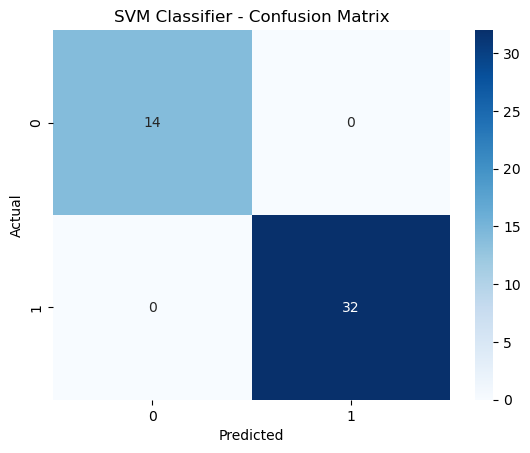

In [136]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, svm_pred_test)

sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('SVM Classifier - Confusion Matrix')
plt.show()

In [137]:
from sklearn.metrics import roc_auc_score, roc_curve

svc_scores = svc.decision_function(x_test_scaled)

svc_auc_score = roc_auc_score(y_test, svc_scores)
svc_auc_score

1.0

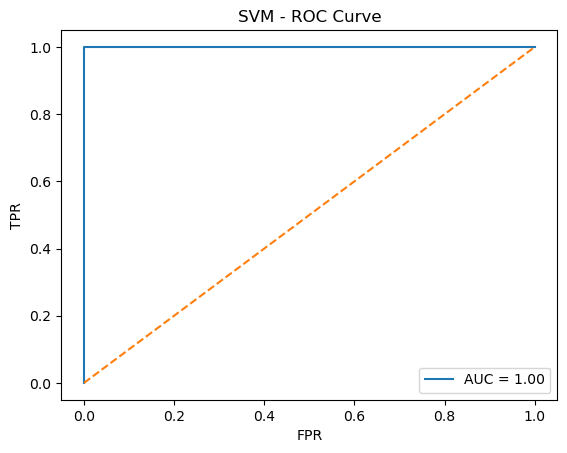

In [138]:
fpr, tpr, thr = roc_curve(y_test, svc_scores)

plt.plot(fpr, tpr, label = f'AUC = {svc_auc_score:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('SVM - ROC Curve')
plt.legend()
plt.show()

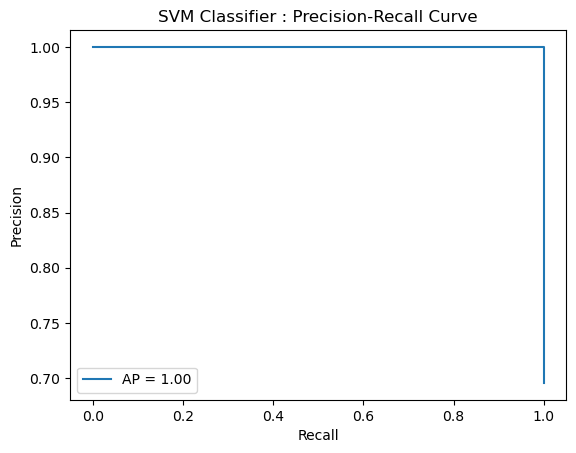

In [139]:
from sklearn.metrics import precision_recall_curve, average_precision_score

svc_scores = svc.decision_function(x_test_scaled)

precision, recall, thresholds = precision_recall_curve(y_test, svc_scores)

ap_score = average_precision_score(y_test, svc_scores)

plt.plot(recall, precision, label = f'AP = {ap_score:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('SVM Classifier : Precision-Recall Curve')
plt.legend()
plt.show()

In [140]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

# Groups corresponding to training data
groups_train = groups[train_idx]

# Stratified Group K-Fold
kfold = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=50
)

# Pipeline
svc_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(kernel='rbf'))
])

cv_svc = cross_validate(
    svc_pipeline,
    x_train,
    y_train,
    groups=groups_train,
    scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'],
    cv=kfold,
    return_train_score=True
)

print("Test Accuracy:", cv_svc['test_accuracy'].mean())
print("Train Accuracy:", cv_svc['train_accuracy'].mean())

print("Test F1:", cv_svc['test_f1'].mean())
print("Train F1:", cv_svc['train_f1'].mean())

print("Test ROC-AUC:", cv_svc['test_roc_auc'].mean())
print("Train ROC-AUC:", cv_svc['train_roc_auc'].mean())

Test Accuracy: 0.9833333333333334
Train Accuracy: 1.0
Test F1: 0.975609756097561
Train F1: 1.0
Test ROC-AUC: 1.0
Train ROC-AUC: 1.0


In [141]:
comparison_svc = pd.DataFrame({
    'Metric': ['Accuracy', 'F1-Score', 'ROC-AUC'],
    'Original Test': [
        accuracy_score(y_test, svm_pred_test),
        f1_score(y_test, svm_pred_test),
        svc_auc_score
    ],
    'Cross Validation': [
        cv_svc['test_accuracy'].mean(),
        cv_svc['test_f1'].mean(),
        cv_svc['test_roc_auc'].mean()
    ]
})

comparison_svc

,Metric,Original Test,Cross Validation
0,Accuracy,1.0,0.983333
1,F1-Score,1.0,0.975610
2,ROC-AUC,1.0,1.000000


### Decision Tree Classifier

In [142]:
from sklearn.tree import DecisionTreeClassifier

dtc = DecisionTreeClassifier(random_state=50)
dtc.fit(x_train, y_train)

dt_train_pred = dtc.predict(x_train)
dt_test_pred = dtc.predict(x_test)

from sklearn.metrics import accuracy_score, f1_score

print("Training Accuracy:", accuracy_score(y_train, dt_train_pred))
print("Testing Accuracy:", accuracy_score(y_test, dt_test_pred))

print("Training F1-Score:", f1_score(y_train, dt_train_pred))
print("Testing F1-Score:", f1_score(y_test, dt_test_pred))

Training Accuracy: 1.0
Testing Accuracy: 1.0
Training F1-Score: 1.0
Testing F1-Score: 1.0


In [143]:
print(classification_report(y_test, dt_test_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        32

    accuracy                           1.00        46
   macro avg       1.00      1.00      1.00        46
weighted avg       1.00      1.00      1.00        46



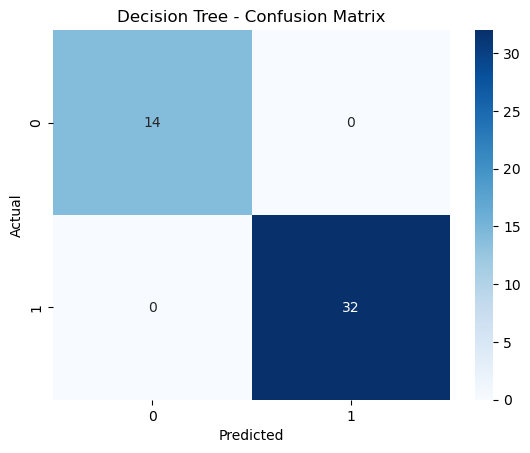

In [144]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, dt_test_pred)

sns.heatmap(cm, annot  =True, fmt = 'd', cmap = 'Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Decision Tree - Confusion Matrix')
plt.show()

In [145]:
from sklearn.metrics import roc_auc_score, roc_curve

dt_scores = dtc.predict_proba(x_test)[:, 1]

dt_auc_score = roc_auc_score(y_test, dt_scores)
dt_auc_score

1.0

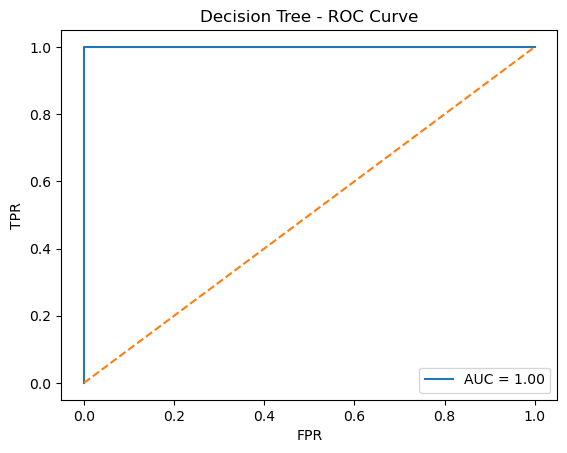

In [146]:
fpr, tpr, thr = roc_curve(y_test, dt_scores)

plt.plot(fpr, tpr, label = f'AUC = {dt_auc_score:.2f}')
plt.plot([0, 1], [0, 1], linestyle = '--')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('Decision Tree - ROC Curve')
plt.legend()
plt.show()

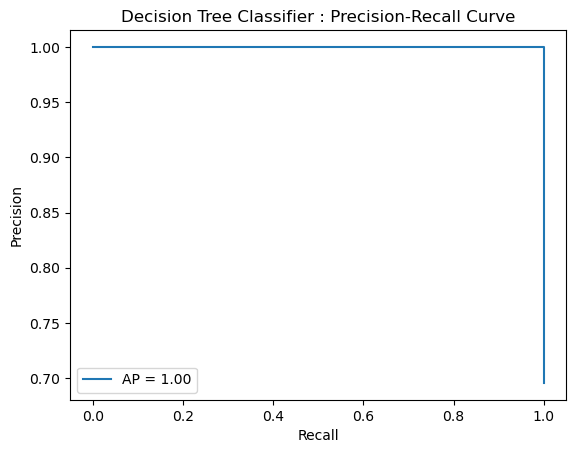

In [147]:
from sklearn.metrics import precision_recall_curve, average_precision_score

dt_scores = dtc.predict_proba(x_test)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_test, dt_scores)

ap_score = average_precision_score(y_test, dt_scores)

plt.plot(recall, precision, label = f'AP = {ap_score:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Decision Tree Classifier : Precision-Recall Curve')
plt.legend()
plt.show()

In [148]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

DT = DecisionTreeClassifier(random_state=50)

params = {
    'criterion': ['gini', 'entropy'],
    'splitter': ['best', 'random'],
    'max_depth': range(1, 10),
    'min_samples_split': [2, 5, 10]
}

grid_search_dt = GridSearchCV(
    estimator=DT,
    param_grid=params,
    scoring='f1',
    cv=kfold,
    n_jobs=-1
)

grid_search_dt.fit(
    x_train,
    y_train,
    groups=groups_train
)

,estimator,DecisionTreeC...ndom_state=50)
,param_grid,"{'criterion': ['gini', 'entropy'], 'max_depth': range(1, 10), 'min_samples_split': [2, 5, ...], 'splitter': ['best', 'random']}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,StratifiedGro... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


In [149]:
grid_search_dt.best_params_

{'criterion': 'gini',
 'max_depth': 1,
 'min_samples_split': 2,
 'splitter': 'best'}

In [150]:
DT = grid_search_dt.best_estimator_

In [151]:
cv_dt = cross_validate(
    dtc,
    x_train,
    y_train,
    groups=groups_train,
    scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'],
    cv=kfold,
    return_train_score=True
)

print("Test Accuracy:", cv_dt['test_accuracy'].mean())
print("Train Accuracy:", cv_dt['train_accuracy'].mean())

print("Test F1:", cv_dt['test_f1'].mean())
print("Train F1:", cv_dt['train_f1'].mean())

print("Test ROC-AUC:", cv_dt['test_roc_auc'].mean())
print("Train ROC-AUC:", cv_dt['train_roc_auc'].mean())

Test Accuracy: 0.9574242424242424
Train Accuracy: 1.0
Test F1: 0.9566970618034448
Train F1: 1.0
Test ROC-AUC: 0.9689182194616978
Train ROC-AUC: 1.0


In [152]:
# Predictions from tuned Decision Tree
dt_tuned_pred = DT.predict(x_test)

# Calculate tuned model ROC-AUC
dt_tuned_scores = DT.predict_proba(x_test)[:, 1]
dt_tuned_auc = roc_auc_score(y_test, dt_tuned_scores)

# Compare Original vs GridSearchCV model
comparison_dt = pd.DataFrame({
    'Metric': ['Accuracy', 'F1-Score', 'ROC-AUC'],

    'Original Test': [
        accuracy_score(y_test, dt_test_pred),
        f1_score(y_test, dt_test_pred),
        dt_auc_score
    ],

    'GridSearchCV Test': [
        accuracy_score(y_test, dt_tuned_pred),
        f1_score(y_test, dt_tuned_pred),
        dt_tuned_auc
    ]
})

comparison_dt

,Metric,Original Test,GridSearchCV Test
0,Accuracy,1.0,1.0
1,F1-Score,1.0,1.0
2,ROC-AUC,1.0,1.0


### Random Forest

In [153]:
from sklearn.ensemble import RandomForestClassifier

rfc = RandomForestClassifier(random_state = 50)
rfc.fit(x_train, y_train)

rf_train_pred = rfc.predict(x_train)
rf_test_pred = rfc.predict(x_test)

from sklearn.metrics import accuracy_score, f1_score

print("Training Accuracy:", accuracy_score(y_train, rf_train_pred))
print("Testing Accuracy:", accuracy_score(y_test, rf_test_pred))

print("Training F1-Score:", f1_score(y_train, rf_train_pred))
print("Testing F1-Score:", f1_score(y_test, rf_test_pred))

Training Accuracy: 1.0
Testing Accuracy: 1.0
Training F1-Score: 1.0
Testing F1-Score: 1.0


In [154]:
print(classification_report(y_test, rf_test_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        32

    accuracy                           1.00        46
   macro avg       1.00      1.00      1.00        46
weighted avg       1.00      1.00      1.00        46



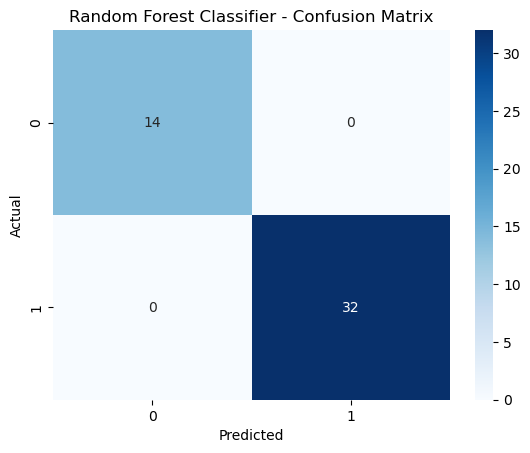

In [155]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, rf_test_pred)

sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest Classifier - Confusion Matrix')
plt.show()

In [156]:
from sklearn.metrics import roc_auc_score, roc_curve

rf_scores = rfc.predict_proba(x_test)[:, 1]

rf_auc_score = roc_auc_score(y_test, rf_scores)
rf_auc_score

1.0

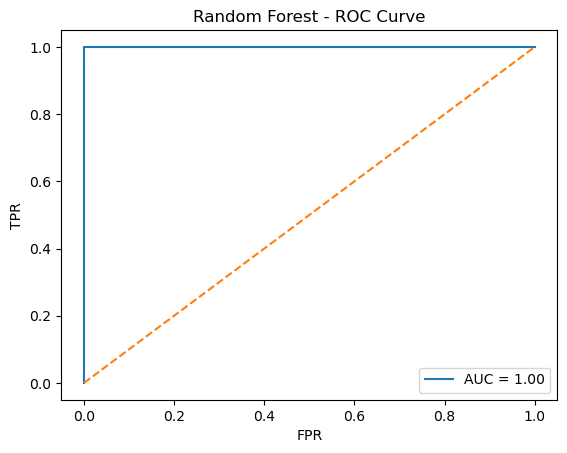

In [157]:
fpr, tpr, thr = roc_curve(y_test, rf_scores)

plt.plot(fpr, tpr, label = f'AUC = {rf_auc_score:.2f}')
plt.plot([0, 1], [0, 1], linestyle = '--')

plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('Random Forest - ROC Curve')
plt.legend()
plt.show()

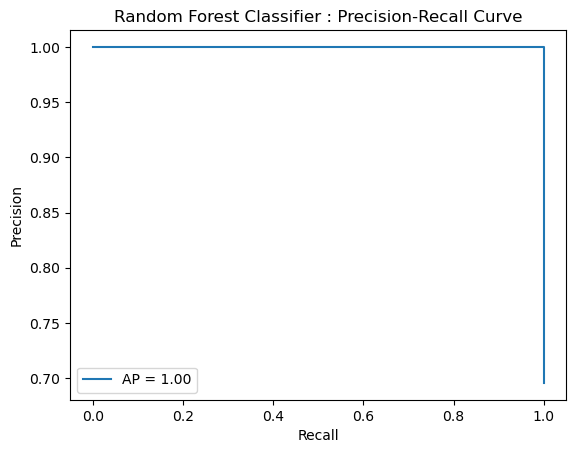

In [158]:
from sklearn.metrics import precision_recall_curve, average_precision_score

rf_scores = rfc.predict_proba(x_test)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_test, rf_scores)

ap_score = average_precision_score(y_test, rf_scores)

plt.plot(recall, precision, label = f'AP = {ap_score:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Random Forest Classifier : Precision-Recall Curve')
plt.legend()
plt.show()

In [159]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

kfold = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=50
)

cv_rf = cross_validate(
    rfc,
    x_train,
    y_train,
    groups=groups_train,
    scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'],
    cv=kfold,
    return_train_score=True
)

print("Test Accuracy:", cv_rf['test_accuracy'].mean())
print("Train Accuracy:", cv_rf['train_accuracy'].mean())

print("Test F1:", cv_rf['test_f1'].mean())
print("Train F1:", cv_rf['train_f1'].mean())

print("Test ROC-AUC:", cv_rf['test_roc_auc'].mean())
print("Train ROC-AUC:", cv_rf['train_roc_auc'].mean())

Test Accuracy: 0.9816666666666667
Train Accuracy: 1.0
Test F1: 0.9757446808510638
Train F1: 1.0
Test ROC-AUC: 1.0
Train ROC-AUC: 1.0


In [160]:
comparison_rf = pd.DataFrame({
    'Metric': ['Accuracy', 'F1-Score', 'ROC-AUC'],
    'Original Test': [
        accuracy_score(y_test, rf_test_pred),
        f1_score(y_test, rf_test_pred),
        rf_auc_score
    ],
    'Cross Validation': [
        cv_rf['test_accuracy'].mean(),
        cv_rf['test_f1'].mean(),
        cv_rf['test_roc_auc'].mean()
    ]
})

comparison_rf

,Metric,Original Test,Cross Validation
0,Accuracy,1.0,0.981667
1,F1-Score,1.0,0.975745
2,ROC-AUC,1.0,1.000000


### Gradient Boost Classifier 

In [161]:
from sklearn.ensemble import GradientBoostingClassifier

gbc = GradientBoostingClassifier(random_state = 50)
gbc.fit(x_train, y_train)

gb_train_pred = gbc.predict(x_train)
gb_test_pred = gbc.predict(x_test)

from sklearn.metrics import accuracy_score, f1_score

print("Training Accuracy:", accuracy_score(y_train, gb_train_pred))
print("Testing Accuracy:", accuracy_score(y_test, gb_test_pred))

print("Training F1-Score:", f1_score(y_train, gb_train_pred))
print("Testing F1-Score:", f1_score(y_test, gb_test_pred))

Training Accuracy: 1.0
Testing Accuracy: 1.0
Training F1-Score: 1.0
Testing F1-Score: 1.0


In [162]:
print(classification_report(y_test, gb_test_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        32

    accuracy                           1.00        46
   macro avg       1.00      1.00      1.00        46
weighted avg       1.00      1.00      1.00        46



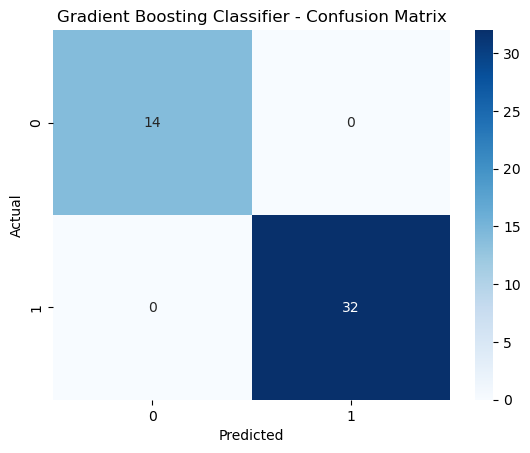

In [163]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, gb_test_pred)

sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Gradient Boosting Classifier - Confusion Matrix')
plt.show()

In [164]:
from sklearn.metrics import roc_auc_score, roc_curve

gb_scores = gbc.predict_proba(x_test)[:, 1]

gb_auc_score = roc_auc_score(y_test, gb_scores)
gb_auc_score

1.0

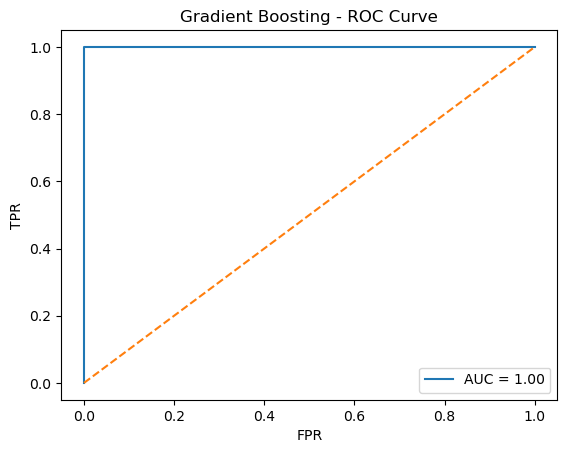

In [165]:
fpr, tpr, thr = roc_curve(y_test, gb_scores)

plt.plot(fpr, tpr, label = f'AUC = {gb_auc_score:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('Gradient Boosting - ROC Curve')
plt.legend()
plt.show()

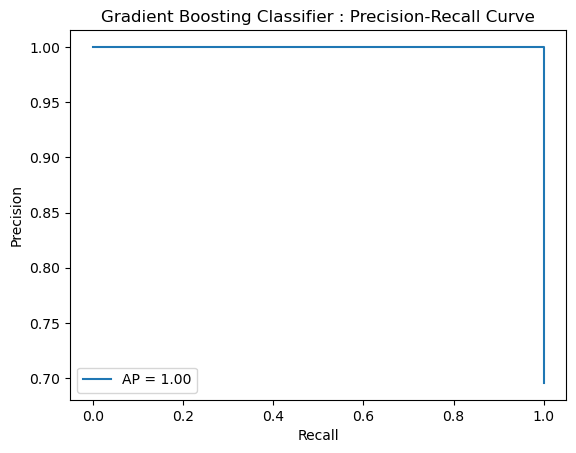

In [166]:
from sklearn.metrics import precision_recall_curve, average_precision_score

gb_scores = gbc.predict_proba(x_test)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_test, gb_scores)

ap_score = average_precision_score(y_test, gb_scores)

plt.plot(recall, precision, label = f'AP = {ap_score:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Gradient Boosting Classifier : Precision-Recall Curve')
plt.legend()
plt.show()

In [167]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

kfold = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=50
)

cv_gb = cross_validate(
    gbc,
    x_train,
    y_train,
    groups=groups_train,
    scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'],
    cv=kfold,
    return_train_score=True
)

print("Test Accuracy:", cv_gb['test_accuracy'].mean())
print("Train Accuracy:", cv_gb['train_accuracy'].mean())

print("Test F1:", cv_gb['test_f1'].mean())
print("Train F1:", cv_gb['train_f1'].mean())

print("Test ROC-AUC:", cv_gb['test_roc_auc'].mean())
print("Train ROC-AUC:", cv_gb['train_roc_auc'].mean())

Test Accuracy: 0.9487285902503293
Train Accuracy: 1.0
Test F1: 0.9512916563980394
Train F1: 1.0
Test ROC-AUC: 0.9821428571428571
Train ROC-AUC: 1.0


In [168]:
comparison_gb = pd.DataFrame({
    'Metric': ['Accuracy', 'F1-Score', 'ROC-AUC'],
    'Original Test': [
        accuracy_score(y_test, gb_test_pred),
        f1_score(y_test, gb_test_pred),
        gb_auc_score
    ],
    'Cross Validation': [
        cv_gb['test_accuracy'].mean(),
        cv_gb['test_f1'].mean(),
        cv_gb['test_roc_auc'].mean()
    ]
})

comparison_gb

,Metric,Original Test,Cross Validation
0,Accuracy,1.0,0.948729
1,F1-Score,1.0,0.951292
2,ROC-AUC,1.0,0.982143


### XGBoost Classifier

In [169]:
!pip install xgboost

In [170]:
from xgboost import XGBClassifier

xgb = XGBClassifier(random_state = 50)

xgb.fit(x_train, y_train)

xgb_train_pred = xgb.predict(x_train)
xgb_test_pred = xgb.predict(x_test)

from sklearn.metrics import accuracy_score, f1_score

print("Training Accuracy:", accuracy_score(y_train, xgb_train_pred))
print("Testing Accuracy:", accuracy_score(y_test, xgb_test_pred))

print("Training F1-Score:", f1_score(y_train, xgb_train_pred))
print("Testing F1-Score:", f1_score(y_test, xgb_test_pred))

Training Accuracy: 1.0
Testing Accuracy: 1.0
Training F1-Score: 1.0
Testing F1-Score: 1.0


In [171]:
print(classification_report(y_test, xgb_test_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        32

    accuracy                           1.00        46
   macro avg       1.00      1.00      1.00        46
weighted avg       1.00      1.00      1.00        46



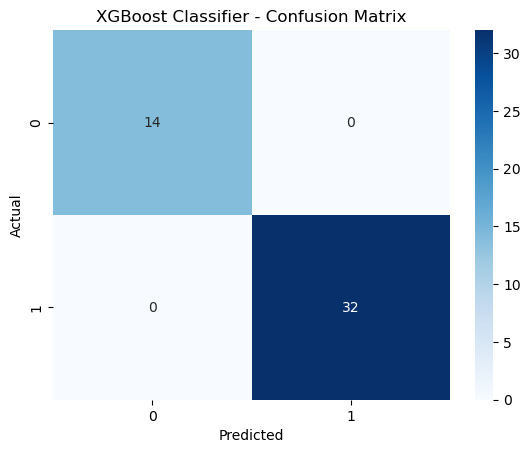

In [172]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, xgb_test_pred)

sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('XGBoost Classifier - Confusion Matrix')
plt.show()

In [173]:
from sklearn.metrics import roc_auc_score, roc_curve

xgb_scores = xgb.predict_proba(x_test)[:, 1]

xgb_auc_score = roc_auc_score(y_test, xgb_scores)
xgb_auc_score

1.0

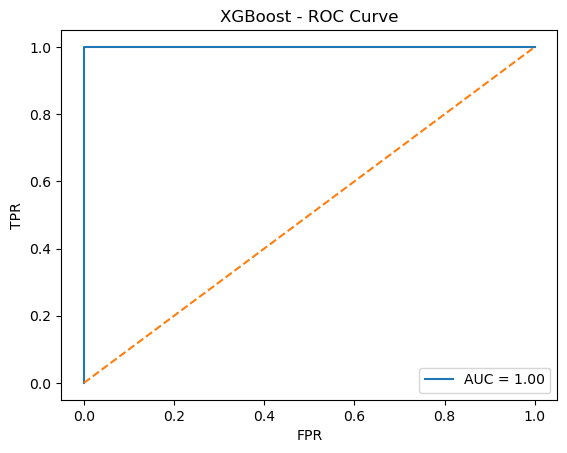

In [174]:
fpr, tpr, thr = roc_curve(y_test, xgb_scores)

plt.plot(fpr, tpr, label = f'AUC = {xgb_auc_score:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('XGBoost - ROC Curve')
plt.legend()
plt.show()

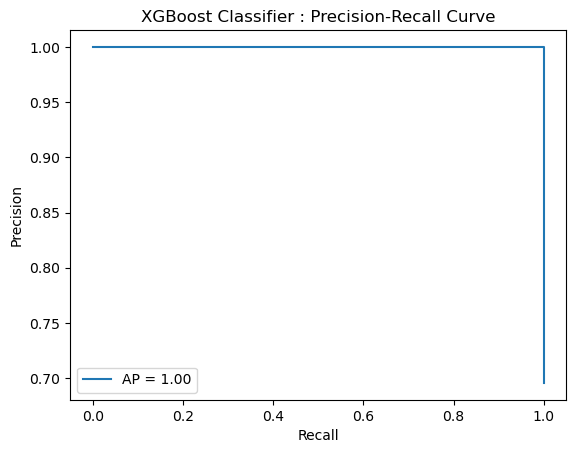

In [175]:
from sklearn.metrics import precision_recall_curve, average_precision_score

xgb_scores = xgb.predict_proba(x_test)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_test, xgb_scores)

ap_score = average_precision_score(y_test, xgb_scores)

plt.plot(recall, precision, label = f'AP = {ap_score:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('XGBoost Classifier : Precision-Recall Curve')
plt.legend()
plt.show()

In [176]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

kfold = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=50
)

cv_xgb = cross_validate(
    xgb,
    x_train,
    y_train,
    groups=groups_train,
    scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'],
    cv=kfold,
    return_train_score=True
)

print("Test Accuracy:", cv_xgb['test_accuracy'].mean())
print("Train Accuracy:", cv_xgb['train_accuracy'].mean())

print("Test F1:", cv_xgb['test_f1'].mean())
print("Train F1:", cv_xgb['train_f1'].mean())

print("Test ROC-AUC:", cv_xgb['test_roc_auc'].mean())
print("Train ROC-AUC:", cv_xgb['train_roc_auc'].mean())

Test Accuracy: 0.9756060606060606
Train Accuracy: 1.0
Test F1: 0.9713002364066193
Train F1: 1.0
Test ROC-AUC: 0.9904761904761905
Train ROC-AUC: 1.0


In [177]:
comparison_xgb = pd.DataFrame({
    'Metric': ['Accuracy', 'F1-Score', 'ROC-AUC'],
    'Original Test': [
        accuracy_score(y_test, xgb_test_pred),
        f1_score(y_test, xgb_test_pred),
        xgb_auc_score
    ],
    'Cross Validation': [
        cv_xgb['test_accuracy'].mean(),
        cv_xgb['test_f1'].mean(),
        cv_xgb['test_roc_auc'].mean()
    ]
})

comparison_xgb

,Metric,Original Test,Cross Validation
0,Accuracy,1.0,0.975606
1,F1-Score,1.0,0.971300
2,ROC-AUC,1.0,0.990476


### Model Training and Evaluation Approach

I trained and evaluated **six classification models** using the prepared training data. Models sensitive to feature scaling were trained using StandardScaler, while tree-based models used the original feature values.

For each model, I performed the following evaluations:

- **Classification Report:** Examined precision, recall and F1-score for both classes.
- **Confusion Matrix:** Checked correct and incorrect predictions.
- **ROC-AUC and ROC Curve:** Evaluated how effectively the model distinguishes between the two classes.
- **Precision-Recall Curve:** Examined the relationship between precision and recall at different thresholds.
- **Cross-Validation:** Used **StratifiedGroupKFold** to compare model performance across multiple folds while maintaining class proportions and keeping identical feature profiles together.

Additionally, I performed **feature coefficient analysis** for Logistic Regression and **hyperparameter tuning using GridSearchCV** for Decision Tree.

Finally, I compared all six models using cross-validation scores to identify the best-performing model.

In [178]:
comparison_all = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'SVM',
        'Decision Tree',
        'Random Forest',
        'Gradient Boosting',
        'XGBoost'
    ],

    'CV Accuracy': [
        cv['test_accuracy'].mean(),
        cv_svc['test_accuracy'].mean(),
        cv_dt['test_accuracy'].mean(),
        cv_rf['test_accuracy'].mean(),
        cv_gb['test_accuracy'].mean(),
        cv_xgb['test_accuracy'].mean()
    ],

    'CV Precision': [
        cv['test_precision'].mean(),
        cv_svc['test_precision'].mean(),
        cv_dt['test_precision'].mean(),
        cv_rf['test_precision'].mean(),
        cv_gb['test_precision'].mean(),
        cv_xgb['test_precision'].mean()
    ],

    'CV Recall': [
        cv['test_recall'].mean(),
        cv_svc['test_recall'].mean(),
        cv_dt['test_recall'].mean(),
        cv_rf['test_recall'].mean(),
        cv_gb['test_recall'].mean(),
        cv_xgb['test_recall'].mean()
    ],

    'CV F1-Score': [
        cv['test_f1'].mean(),
        cv_svc['test_f1'].mean(),
        cv_dt['test_f1'].mean(),
        cv_rf['test_f1'].mean(),
        cv_gb['test_f1'].mean(),
        cv_xgb['test_f1'].mean()
    ],

    'CV ROC-AUC': [
        cv['test_roc_auc'].mean(),
        cv_svc['test_roc_auc'].mean(),
        cv_dt['test_roc_auc'].mean(),
        cv_rf['test_roc_auc'].mean(),
        cv_gb['test_roc_auc'].mean(),
        cv_xgb['test_roc_auc'].mean()
    ]
})

comparison_all.sort_values(by = 'CV F1-Score', ascending = False)

,Model,CV Accuracy,CV Precision,CV Recall,CV F1-Score,CV ROC-AUC
0,Logistic Regression,0.991667,0.989474,0.991667,0.990339,0.998942
3,Random Forest,0.981667,0.963636,0.991667,0.975745,1.000000
1,SVM,0.983333,0.956522,1.000000,0.975610,1.000000
5,XGBoost,0.975606,0.963636,0.982971,0.971300,0.990476
2,Decision Tree,0.957424,0.963636,0.956884,0.956697,0.968918
4,Gradient Boosting,0.948729,0.963636,0.946358,0.951292,0.982143


### Cross-Validation Results ~ Model Comparison

The cross-validation results show how consistently the six models performed across different training and validation folds.

- **Logistic Regression** achieved the highest CV Accuracy (0.9917), Precision (0.9895) and F1-Score (0.9903), showing the strongest overall balance.
- **Decision Tree and SVM** achieved the highest Recall (1.0000), indicating that they identified all positive-class cases across the evaluated folds.
- **Random Forest and SVM** achieved the highest ROC-AUC (1.0000), showing excellent class separation.
- **Gradient Boosting** recorded the lowest CV Accuracy (0.9487) and F1-Score (0.9513) among the six models.

Overall, **Logistic Regression emerged as the strongest model** based on its consistently high accuracy, precision and F1-score, although other models performed better on individual metrics.

In [179]:
final_model = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression())
])

final_model.fit(x_train, y_train)

,steps,"[('scaler', ...), ('lr', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [180]:
import os

print(os.getcwd())

C:\Users\Harsha


In [181]:
import joblib

joblib.dump(final_model, "bankruptcy_model.pkl")

['bankruptcy_model.pkl']

In [182]:
print(os.path.exists("bankruptcy_model.pkl"))

True


### Final Model Training and Saving

After comparing all six models, I selected **Logistic Regression** as the final model based on its overall cross-validation performance.

I created a **Pipeline** combining `StandardScaler` and `LogisticRegression` to ensure that scaling is automatically applied before making predictions.

Finally, I used **Joblib** to save the trained pipeline as `bankruptcy_model.pkl`. This allows the model to be reused in the Streamlit application without needing to train it again.